In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
tf.random.set_seed(42)

# Geração dos pontos a partir do Modelo

${k_{ro}} = {k_{ro\max }}{\left( {\dfrac{{{S_o} - {S_{or}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_o}}} = {k_{ro\max }}{\left( {\dfrac{{1 - {S_w} - {S_{or}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_o}}}$

$$ $$

${k_{rw}} = {k_{rw\max }}{\left( {\dfrac{{{S_w} - {S_{wi}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_w}}}$

In [16]:
def curva_permeabilidade(k_romax = 0.5, Sor = 0.2, no = 3.,
                         k_rwmax = 0.4, Swi = 0.3, nw = 2.,
                         Sw = np.linspace(0, 1, 11)):
    
    
    num = 1 - Sw  - Sor
    den = 1 - Sor - Swi
    k_ro = k_romax * ( num / den ) ** no

    num2 = Sw  - Swi
    k_rw = k_rwmax * ( num2 / den ) ** nw

    antes = np.where( Sw <= Swi )[0]
    x0 = Sw[antes[-1]]
    y0o = k_ro[antes[-1]]
    y0w = k_rw[antes[-1]]

    depois = np.where( Sw >= 1-Sor )[0]
    xf = Sw[depois[0]]
    yfo = k_ro[depois[0]]
    yfw = k_rw[depois[0]]

    pontos = (x0, xf, y0o, y0w, yfo, yfw)

    k_ro  = np.delete(k_ro, antes, 0)
    k_rw  = np.delete(k_rw, antes, 0)
    k_ro  = np.delete(k_ro, depois, 0)
    k_rw  = np.delete(k_rw, depois, 0)

    # Sw = np.delete(Sw, antes, 1)
    # Sw = np.delete(Sw, depois, 1)
    print(Sw)

    return [Sw, k_ro, k_rw, pontos]
    

# Gráfico a partir dos pontos gerados

In [17]:
def grafico_permeabilidades( Sw     = np.linspace(0, 1, 11), 
                             k_ro   = np.linspace(0, 1, 11), 
                             k_rw   = np.linspace(0, 1, 11), 
                             pontos = (0.1, 0.8, 0.7, 0.0, 1e-10, 0.5),
                             cor    = (0, 1, 0), rotulo='sal'):
    
    (x0, xf, y0o, y0w, yfo, yfw) = pontos
    ax.plot(Sw, k_ro, label=rotulo, color=cor, ls=':' , lw=0.5)
    ax.plot(Sw, k_rw,               color=cor, ls='--', lw=0.5)
    ax.scatter(x0, y0o, s=10, lw=0, color=cor, alpha=0.5)
    ax.scatter(xf, yfo, s=10, lw=0, color=cor, alpha=0.5)
    ax.scatter(x0, y0w, s=10, lw=0, color=cor, alpha=0.5)
    ax.scatter(xf, yfw, s=10, lw=0, color=cor, alpha=0.5)
    ax.legend(fontsize=3)
    ax.set_xlabel("$S_w$")
    ax.set_ylabel("$K_r$")

IndexError: ignored

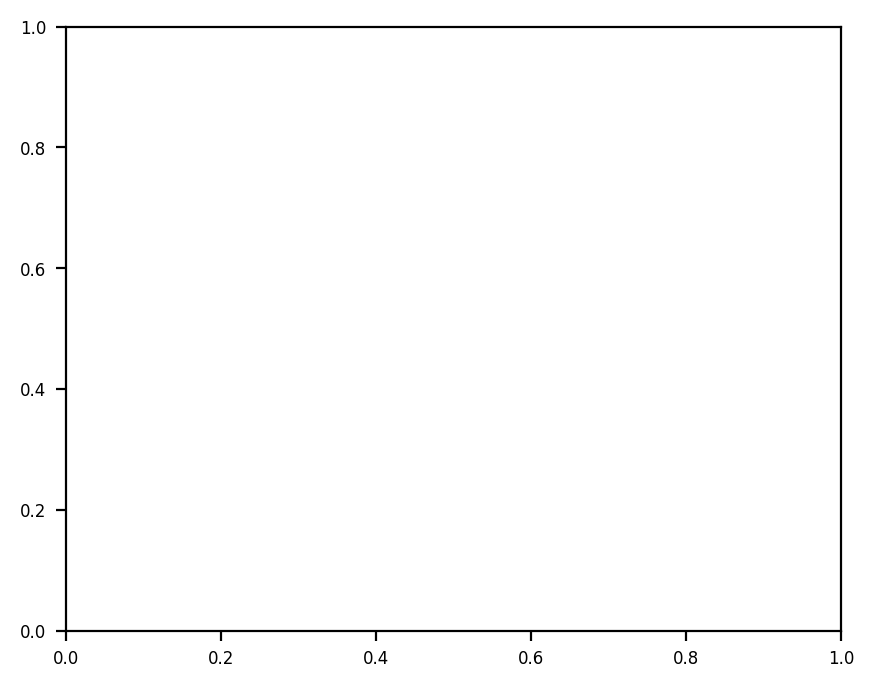

In [19]:
xx = np.linspace(0, 1, 111)
nn = 1
X = np.ones( ( nn, len(xx)+1 ) )
Y = np.ones( ( nn, len(xx)+6 ) )
   
salin = np.linspace(0.1, 0.5, nn)
k_romax = 0.7
k_rwmax = 0.5
Sor_0     = 0.6
Swi_0     = 0.2
no = 3.
nw = 2.

fig, ax = plt.subplots(figsize=(5,4), dpi=200)
plt.rcParams["font.size"] = 6

for ii in range(nn):
    Sor     = Sor_0 - salin[ii]
    Swi     = Swi_0 + salin[ii]
    
    [Sw, k_ro, k_rw, pontos] = curva_permeabilidade(k_romax = k_romax, Sor = Sor, no = no,
                                                k_rwmax = k_rwmax, Swi = Swi, nw = nw,
                                                Sw = np.linspace(0, 1, 11))
    
    # para rede neural    
    # X[ii,0:len(Sw)] = Sw
    # X[ii,len(Sw)] = salin[ii]
    

    # Y[ii,0:len(Sw)] = k_ro
    # Y[ii,len(Sw)-1:-1] = np.array([Sor, k_romax, no, Swi, k_rwmax, nw])
    
    # if( np.mod(ii,2)==0 ):
    #     cor = (0, ii/len(salin), 0)
    # elif( np.mod(ii, 3)==0 ):
    #     cor = (0, 0, ii/len(salin))
    # else:
    #     cor = (ii/len(salin), 0, 0)

    # grafico_permeabilidades(Sw=Sw, k_ro=k_ro, k_rw=k_rw, pontos=pontos, rotulo=str(salin[ii]), cor=cor)


In [ ]:
X

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(2*X.shape[1], activation='linear'),
    tf.keras.layers.Dense(2*X.shape[1], activation='linear'),
    tf.keras.layers.Dense(Y.shape[1], activation='linear')
])

In [ ]:
model.compile(loss=tf.keras.losses.mse,
              optimizer=tf.keras.optimizers.Adamax(learning_rate=0.001), 
              metrics=["mse","mae"])

In [ ]:
# Fit the model
history = model.fit(X, Y, epochs=2000, verbose=0)
print("treinada...")

In [ ]:
model.summary()

In [ ]:
fig, ax = plt.subplots(figsize=(3,1), dpi=300)
ax.plot(history.history["mse"], label="mse")
ax.plot(history.history["mae"], label="mae")
ax.set_ylim(-0.1, 0.2)
ax.legend()

In [ ]:
X_pred = X
salin_pred = X_pred[:,-1]
Sw_pred = Sw
Y_pred = model.predict(X_pred)

In [ ]:
Y_pred.shape[1]

In [ ]:
yy = Y_pred[ii, Y_pred.shape[1]-7:-1]
yy

In [ ]:
np.array(pontos)

In [ ]:
xx = ['Sor', 'k_romax', 'no', 'Swi', 'k_rwmax', 'nw']
for ii in range(len(xx)):
    yy_rede = Y_pred[ii, Y_pred.shape[1]-7:-1]
    yy_orig = Y[ii, Y.shape[1]-7:-1]
    plt.scatter(yy_rede, yy_orig, label=xx[ii])
    plt.legend()


In [ ]:

for ii in range(nn):
    fig2, ax2 = plt.subplots(dpi=100, figsize=(4,1))
    yy_rede = Y_pred[ii, Y_pred.shape[1]-7:-1]
    yy_orig = Y[ii, Y.shape[1]-7:-1]
    barWidth = 0.8
    ax2.set_title('Salinidade '+str(ii))
    ax2.bar(xx, yy_rede, width = barWidth, label='rede')
    ax2.bar(xx, yy_orig, width = barWidth/4, label='orig')    
ax2.legend()

In [ ]:
salin = np.round(salin, 1)
for ii in range(nn):
    yy_rede = Y_pred[ii, 0:len(Sw)]
    yy_orig = Y[ii, 0:len(Sw)]
    plt.plot(Sw, yy_orig, label='orig_sal='+str(salin[ii]))
    plt.plot(Sw, yy_rede, ls="--")
plt.legend()